# Внешняя оценка за 2019 год

**Козлов Кирилл Андреевич.** [Основная v2](../experiments.ipynb) · [README](README.md) ·
[Источник](https://amazon-reviews-2023.github.io/main.html) · [Протокол](reports/protocol.json).

Пять моделей переобучены с гиперпараметрами v2. Подбор и early stopping не выполнялись.
Fit — до 2019-01-01 UTC, test — 2019 год. Отбор только по fit; ID из выпуска 2023.

Обучение и оценка: `run_final.py`. Пересборка отчёта без данных и весов из корня репозитория:
`python homework_1/external_2019/render.py`.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
assert (ROOT/'reports/final/summary.json').is_file(), 'Рабочая папка — homework_1/external_2019'
P = ROOT/'reports/final'
summary = json.loads((P/'summary.json').read_text())
protocol = json.loads((ROOT/'reports/protocol.json').read_text())
assert hashlib.sha256((ROOT/'reports/protocol.json').read_bytes()).hexdigest() == summary['protocol_sha256']
assert summary['completed_refits']==5 and summary['completed_test_evaluations']==6
for rel, digest in summary['artifact_hashes'].items():
    if rel.startswith('data/'): continue
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==digest, rel
comparison = pd.read_csv(P/'comparison.csv')
intervals = pd.read_csv(P/'bootstrap_vs_EASE.csv')
colors = ['#7B8794','#255F85','#D87535','#3B8C78','#9274A6','#B04D55']
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':110,
                     'axes.spines.top':False,'axes.spines.right':False})
(ROOT/'reports/figures').mkdir(exist_ok=True)
def figure(name, fig):
    fig.tight_layout()
    fig.savefig(ROOT/'reports/figures'/f'{name}.png',dpi=145,bbox_inches='tight')
    plt.show(); plt.close(fig)
pd.set_option('display.max_columns',20)
pd.set_option('display.float_format',lambda x:f'{x:.6f}')

## Данные

Fit-only 5-core: 520 585 событий, 59 204 пользователя, 15 650 товаров.
До анализа test-рейтингов найдены 10 092 доступных события любых оценок у 5 536 пользователей.
Окончательная когорта дополнительно требует хотя бы один релевантный товар.

FM использует fit IDs/timestamps: первые календарные даты, количество событий, возраст истории и давность.
Карточки и тексты отзывов исключены. Доступность событий предполагается по timestamp;
исторические редакции рейтингов и parent-связей не восстанавливаются.

In [2]:
display(pd.Series(summary['fit'],name='Новый fit').to_frame())
display(pd.Series(summary['cohort'],name='Общая test-когорта').to_frame())
display(pd.Series(summary['test_scope'],name='Охват test').to_frame())
display(pd.DataFrame([{'model':n,**p} for n,p in protocol['models'].items()]).set_index('model'))
display(pd.Series(summary['refit_manifest']['FM']['diagnostics']['feature_diagnostics'],name='Доступность признаков FM').to_frame())

,Новый fit
events,520585
users,59204
items,15650
max_timestamp,1546300759


,Общая test-когорта
evaluation_users,4477
catalog_items,15650
relevant_interactions,8090
seen_relevant_items_removed,0
users_excluded_for_fewer_than_k_candidates,0
new_user_interactions,422084
new_item_interactions,201073


,Охват test
all_test_events,441337.000000
all_positive_test_events,343073.000000
available_relevant_events,8090.000000
positive_event_coverage,0.023581
selected_all_rating_events_from_feasibility,10092.000000
users_with_any_selected_test_event_from_feasibility,5536.000000


,regularization,batch_size,learning_rate,n_epochs,n_factors,seed,shuffle_seed,n_neighbors,shrinkage,alpha,n_iterations,solver_batch_size,beta,n_bins
model,,,,,,,,,,,,,,
EASE,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FM,0.000010,1024.000000,0.050000,12.000000,16.000000,42.000000,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ItemKNN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,10.000000,NaN,NaN,NaN,NaN,NaN
iALS,0.100000,NaN,NaN,NaN,64.000000,42.000000,NaN,NaN,NaN,40.000000,15.000000,128.000000,NaN,NaN
timeSVD++,0.010000,NaN,0.050000,50.000000,32.000000,42.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.400000,36.000000


,Доступность признаков FM
all_source_timestamps_before_query,True
features,74892
first_month_vocabulary,12
first_year_vocabulary,20
history_age_days_max,7010.094965
history_age_days_min,10.899039
item_id_features,15650
max_active_item_features,6
max_source_timestamp,1546300759
metadata_assumption,timestamp is event availability; no historical...


## Протокол

Запрос — 2019-01-01 UTC, история фиксирована на год. Relevance — rating >= 4.
Кандидаты — полный fit-каталог минус все fit-товары пользователя, включая оценки 1–3.
K=10, ties по item ID, общий popularity fallback без исключения пользователей.
Основная метрика — macro NDCG@10, дополнительная — macro Recall@10.
Гиперпараметры и reference EASE выбраны на исходной validation v2.
Все пять обучений завершены до открытия test-рейтингов.
[Журнал](reports/final/execution_journal.jsonl).

In [3]:
journal = [json.loads(line) for line in (P/'execution_journal.jsonl').read_text().splitlines()]
display(pd.DataFrame([row for row in journal if row['event'] in ['refit_completed','test_unsealed_for_fixed_evaluation','test_read','test_evaluated','final_evaluation_complete_no_choices_changed']])[['event','utc']])
if summary['persistence_recovery']:
    display(Markdown('Ошибка записи CSV после расчёта Popularity. Продолжение: те же веса и протокол, без refit/HPO; повторно вычислен контроль.'))
    display(Markdown('[План продолжения](reports/final/recovery_plan.json)'))
else:
    display(Markdown('Запуск завершён без технического продолжения.'))
verification=json.loads((P/'verification.json').read_text())
display(pd.Series({k:verification[k] for k in ['refits_before_test_access','independent_per_user_metric_rows','independent_bootstrap_difference_intervals_verified','protected_v2_files_unchanged']},name='Проверки').to_frame())

,event,utc
0,refit_completed,2026-10-24T11:48:26.230729+00:00
1,refit_completed,2026-10-24T11:49:28.228641+00:00
2,refit_completed,2026-10-24T11:49:48.783222+00:00
3,refit_completed,2026-10-24T11:50:16.506694+00:00
4,refit_completed,2026-10-24T11:50:24.698945+00:00
5,test_unsealed_for_fixed_evaluation,2026-10-24T11:50:24.711314+00:00
6,test_read,2026-10-24T11:50:24.913773+00:00
7,test_unsealed_for_fixed_evaluation,2026-10-24T11:52:17.703785+00:00
8,test_read,2026-10-24T11:52:17.907045+00:00
9,test_evaluated,2026-10-24T11:52:19.116680+00:00


Ошибка записи CSV после расчёта Popularity. Продолжение: те же веса и протокол, без refit/HPO; повторно вычислен контроль.

[План продолжения](reports/final/recovery_plan.json)

,Проверки
refits_before_test_access,5
independent_per_user_metric_rows,26862
independent_bootstrap_difference_intervals_verified,12
protected_v2_files_unchanged,118


## Результаты

Когорта, кандидаты и релевантность одинаковы для всех моделей.
Прямое сравнение со старым test v2 некорректно: изменились источник, период, fit и пользователи.

,model,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,selected_parameters
0,Popularity,0.015776,0.033007,0.001086,0.000000,4477,0.470143,0.000000,{}
1,ItemKNN,0.019849,0.033658,0.347668,0.003350,4477,0.616976,0.384041,"{""n_neighbors"": 100, ""shrinkage"": 10.0}"
2,iALS,0.021709,0.036727,0.110863,0.003350,4477,0.623873,61.973414,"{""alpha"": 40.0, ""n_factors"": 64, ""n_iterations..."
3,EASE,0.023388,0.040492,0.221022,0.003350,4477,0.842751,18.613413,"{""regularization"": 100.0}"
4,FM,0.010790,0.017999,0.061278,0.000000,4477,0.543853,26.599799,"{""batch_size"": 1024, ""learning_rate"": 0.05, ""n..."
5,timeSVD++,0.000578,0.001097,0.298403,0.000000,4477,0.576191,7.585646,"{""beta"": 0.4, ""learning_rate"": 0.05, ""n_bins"":..."


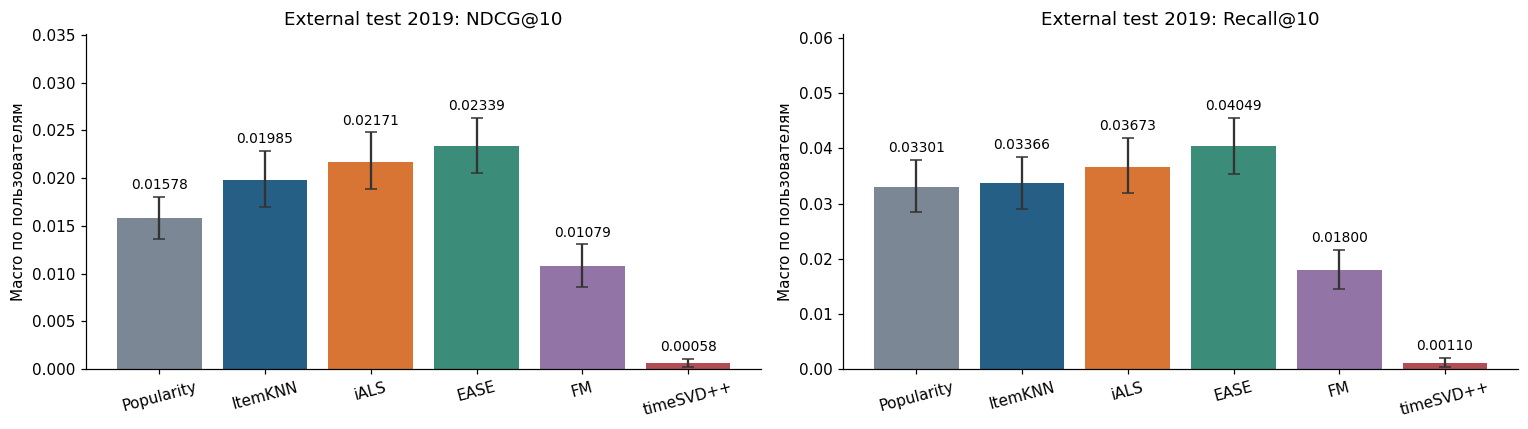

In [4]:
display(comparison.assign(selected_parameters=comparison.model.map(lambda n:json.dumps(protocol['models'].get(n,{}),ensure_ascii=False,sort_keys=True))))
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(comparison.model,comparison[metric],color=colors)
    for j,row in comparison.iterrows():
        ci=intervals[(intervals.comparison==row.model+' - EASE')&(intervals.metric==metric)&(intervals.estimate_for==row.model)].iloc[0]
        ax.errorbar(j,row[metric],yerr=[[max(0,row[metric]-ci.ci_low)],[max(0,ci.ci_high-row[metric])]],fmt='none',ecolor='#333333',capsize=4)
        ax.annotate(f'{row[metric]:.5f}',(j,ci.ci_high),xytext=(0,5),textcoords='offset points',ha='center',fontsize=9)
    ax.set(title='External test 2019: '+label,ylabel='Macro по пользователям',ylim=(0,comparison[metric].max()*1.5));ax.tick_params(axis='x',rotation=15)
figure('01_external_accuracy',fig)

## Парные интервалы

2 000 перевыборок одинаковых пользователей, seed=42, 95% интервалы.
Оценки условны на моделях и когорте; вариация seeds, зависимости пользователей
и множественные сравнения не учтены.

,metric,estimate_for,estimate,ci_low,ci_high,comparison
2,ndcg_at_10,difference,-0.007611,-0.010845,-0.004456,Popularity - EASE
5,recall_at_10,difference,-0.007485,-0.013298,-0.001537,Popularity - EASE
8,ndcg_at_10,difference,-0.003539,-0.005392,-0.001715,ItemKNN - EASE
11,recall_at_10,difference,-0.006833,-0.010514,-0.003341,ItemKNN - EASE
14,ndcg_at_10,difference,-0.001678,-0.004194,0.000671,iALS - EASE
17,recall_at_10,difference,-0.003764,-0.008458,0.000412,iALS - EASE
26,ndcg_at_10,difference,-0.012597,-0.015702,-0.009451,FM - EASE
29,recall_at_10,difference,-0.022492,-0.028259,-0.017074,FM - EASE
32,ndcg_at_10,difference,-0.022810,-0.025792,-0.019819,timeSVD++ - EASE
35,recall_at_10,difference,-0.039394,-0.044540,-0.034209,timeSVD++ - EASE


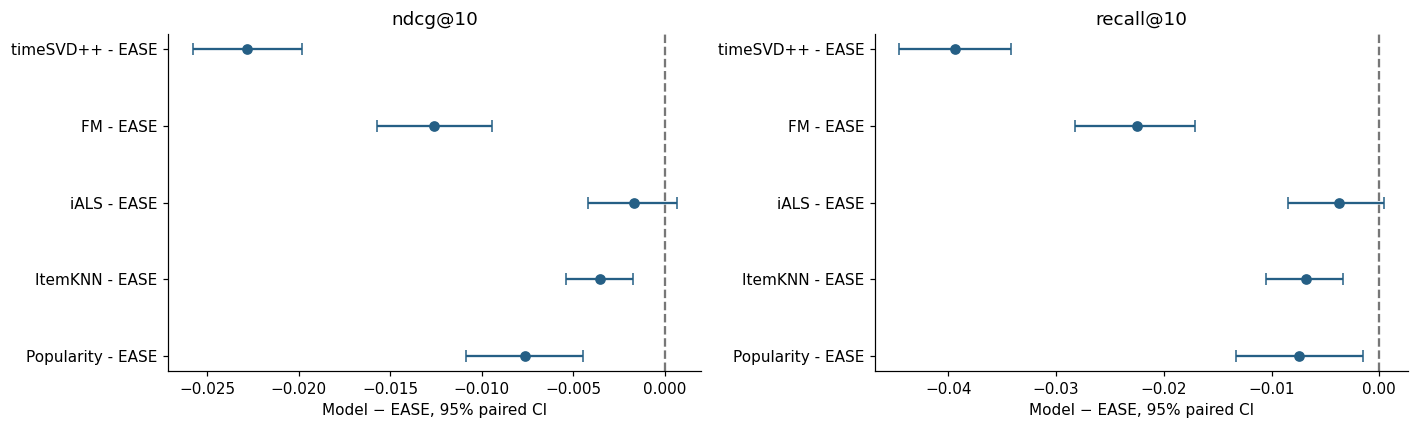

In [5]:
differences=intervals[(intervals.estimate_for=='difference')&(intervals.comparison!='EASE - EASE')]
display(differences)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    t=differences[differences.metric==metric].reset_index(drop=True)
    ax.errorbar(t.estimate,np.arange(len(t)),xerr=[t.estimate-t.ci_low,t.ci_high-t.estimate],fmt='o',capsize=4,color='#255F85')
    ax.axvline(0,color='#777777',ls='--');ax.set_yticks(np.arange(len(t)),t.comparison)
    ax.set(title=metric.replace('_at_','@'),xlabel='Model − EASE, 95% paired CI')
figure('02_external_paired_differences',fig)

## Срезы, coverage и fallback

Группы определены по fit. Head — верхние 10% товаров по числу положительных fit-событий, ties по ID.
Recall среза усредняется по пользователям с релевантностью в нём; группы могут пересекаться.
Группа истории 1–4 пуста из-за fit-only 5-core.
Время обучения исключает общий индекс и специальную подготовку FM/timeSVD++.

,model,history_slice,users,ndcg,recall,fallback_rate
0,Popularity,1-4,0,NaN,NaN,NaN
1,Popularity,5-9,2911,0.015053,0.031821,0.000000
2,Popularity,10+,1566,0.017120,0.035212,0.000000
3,ItemKNN,1-4,0,NaN,NaN,NaN
4,ItemKNN,5-9,2911,0.019118,0.032134,0.005153
5,ItemKNN,10+,1566,0.021208,0.036491,0.000000
6,iALS,1-4,0,NaN,NaN,NaN
7,iALS,5-9,2911,0.022117,0.038719,0.005153
8,iALS,10+,1566,0.020953,0.033025,0.000000
9,EASE,1-4,0,NaN,NaN,NaN


,model,item_slice,users,relevant_interactions,recall_at_10
0,Popularity,head_top_10_percent,2287,3382,0.077151
1,Popularity,tail_other_90_percent,3036,4708,0.000000
2,ItemKNN,head_top_10_percent,2287,3382,0.067568
3,ItemKNN,tail_other_90_percent,3036,4708,0.009699
4,iALS,head_top_10_percent,2287,3382,0.086481
5,iALS,tail_other_90_percent,3036,4708,0.002079
6,EASE,head_top_10_percent,2287,3382,0.085051
7,EASE,tail_other_90_percent,3036,4708,0.007793
8,FM,head_top_10_percent,2287,3382,0.044473
9,FM,tail_other_90_percent,3036,4708,0.000030


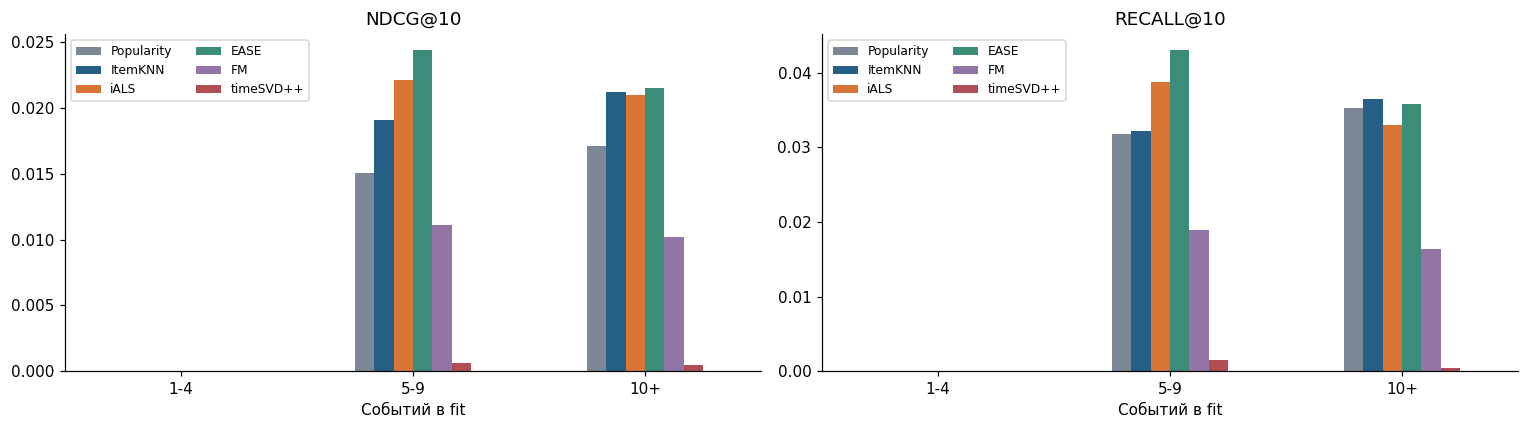

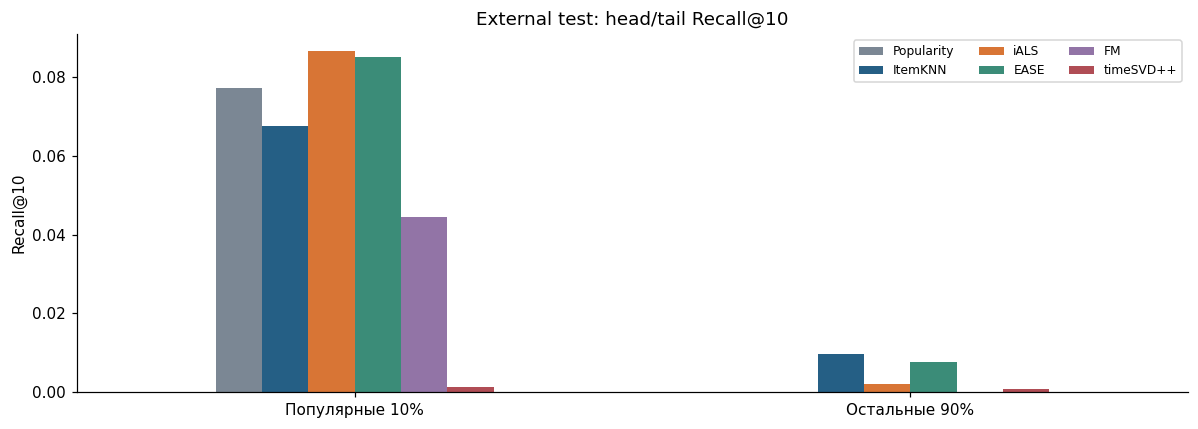

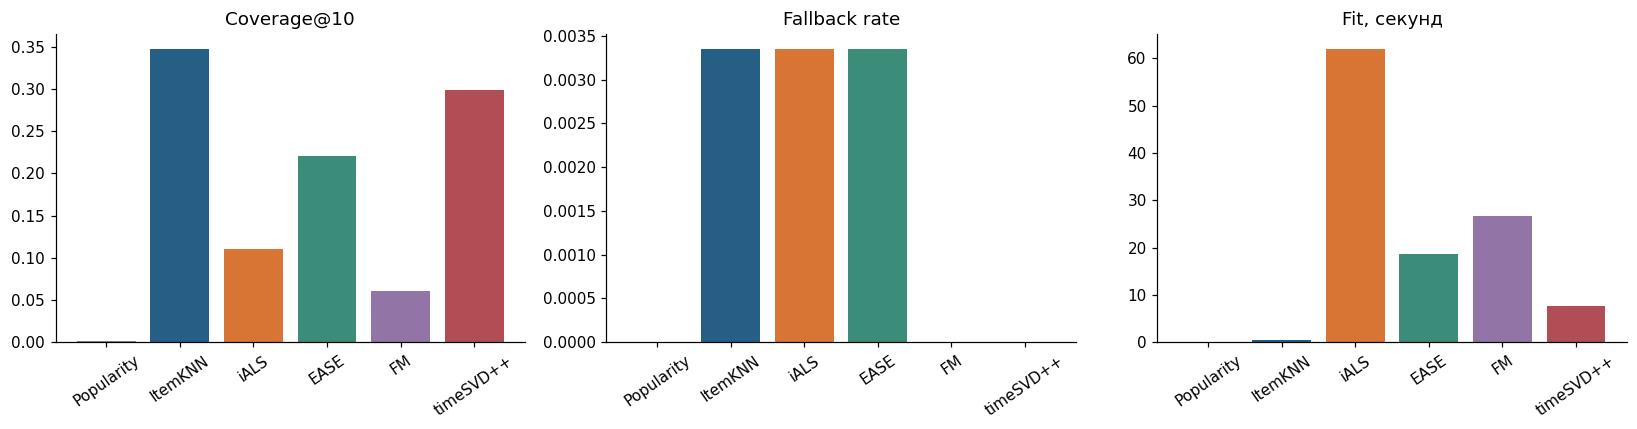

In [6]:
history=pd.read_csv(P/'history_slices.csv');popularity=pd.read_csv(P/'popularity_slices.csv')
display(history);display(popularity)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric in zip(axes,['ndcg','recall']):
    t=history.pivot(index='history_slice',columns='model',values=metric).reindex(['1-4','5-9','10+'])[comparison.model]
    t.plot.bar(ax=ax,color=colors,rot=0);ax.set(title=metric.upper()+'@10',xlabel='Событий в fit');ax.legend(fontsize=8,ncol=2)
figure('03_external_history',fig)
fig,ax=plt.subplots(figsize=(11,4))
t=popularity.pivot(index='item_slice',columns='model',values='recall_at_10').reindex(['head_top_10_percent','tail_other_90_percent'])[comparison.model]
t.index=['Популярные 10%','Остальные 90%'];t.plot.bar(ax=ax,color=colors,rot=0)
ax.set(title='External test: head/tail Recall@10',xlabel='',ylabel='Recall@10');ax.legend(fontsize=8,ncol=3)
figure('04_external_popularity',fig)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric,label in zip(axes,['catalog_coverage_at_10','fallback_rate','fit_seconds'],['Coverage@10','Fallback rate','Fit, секунд']):
    ax.bar(comparison.model,comparison[metric],color=colors);ax.set_title(label);ax.tick_params(axis='x',rotation=35)
figure('05_external_coverage_fallback_cost',fig)

## Обучение

iALS: полная objective. FM: BCE на фиксированной train-подвыборке. timeSVD++: полный train RMSE.
Число шагов фиксировано до запуска. Абсолютные значения разных функций потерь несопоставимы.

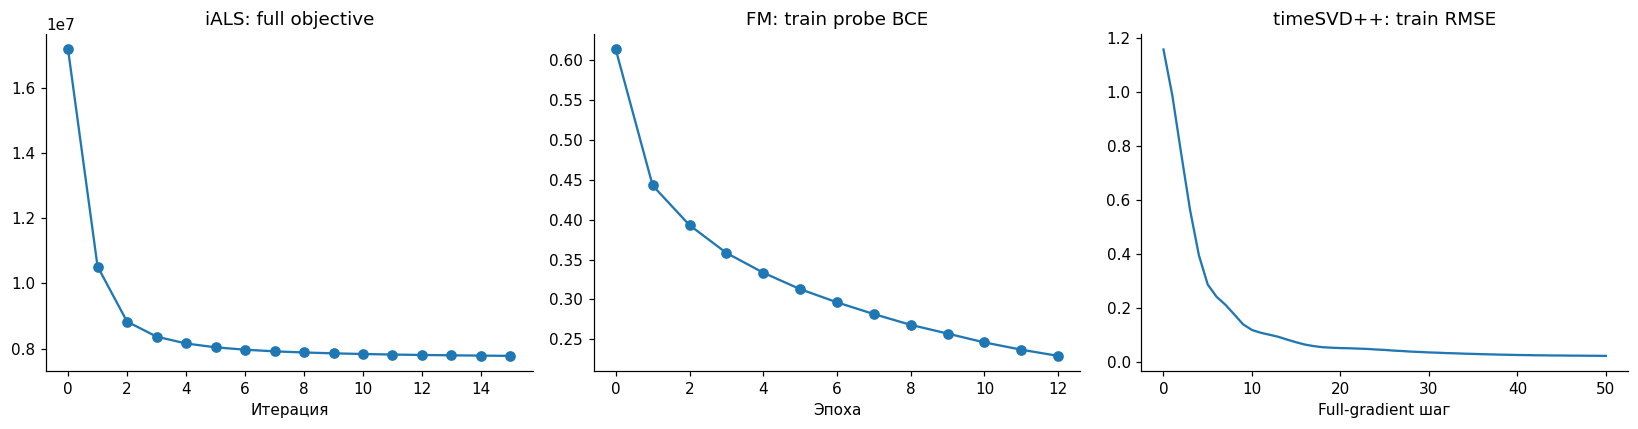

In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
a=pd.read_csv(P/'training_ials.csv');b=pd.read_csv(P/'training_fm.csv');c=pd.read_csv(P/'training_timesvdpp.csv')
axes[0].plot(a.iteration,a.objective,marker='o');axes[0].set(title='iALS: full objective',xlabel='Итерация')
axes[1].plot(b.epoch,b.probe_bce,marker='o');axes[1].set(title='FM: train probe BCE',xlabel='Эпоха')
axes[2].plot(c.epoch,c.training_rmse);axes[2].set(title='timeSVD++: train RMSE',xlabel='Full-gradient шаг')
figure('06_external_training_curves',fig)

## Выводы

In [8]:
ordered=comparison[comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False)
leader=ordered.iloc[0];scope=summary['test_scope']
lines=[]
for name in ordered.model:
    row=intervals[(intervals.comparison==name+' - EASE')&(intervals.metric=='ndcg_at_10')&(intervals.estimate_for=='difference')].iloc[0]
    lines.append(f"- {name} − EASE: {row.estimate:+.6f}, 95% CI [{row.ci_low:.6f}; {row.ci_high:.6f}].")
display(Markdown(f"""
Точечный лидер — **{leader.model}**:
**{leader.ndcg_at_10:.6f}**, Recall@10 **{leader.recall_at_10:.6f}**.
Интервал iALS − EASE включает ноль; превосходство EASE над iALS не установлено.

{chr(10).join(lines)}

Оценено **{summary['cohort']['evaluation_users']} пользователей** и
**{scope['available_relevant_events']} доступных релевантных событий**.
Охват положительных событий всей категории — **{scope['positive_event_coverage']:.2%}**.
Ограничения: известные пользователи и товары, fit-only 5-core, малый охват потока,
отзывы вместо показов/покупок, фиксированная история и один seed.
Test-ablation не проводилась; причинный эффект метаданных и времени здесь не измеряется.
"""))


Точечный лидер — **EASE**:
**0.023388**, Recall@10 **0.040492**.
Интервал iALS − EASE включает ноль; превосходство EASE над iALS не установлено.

- EASE − EASE: +0.000000, 95% CI [0.000000; 0.000000].
- iALS − EASE: -0.001678, 95% CI [-0.004194; 0.000671].
- ItemKNN − EASE: -0.003539, 95% CI [-0.005392; -0.001715].
- FM − EASE: -0.012597, 95% CI [-0.015702; -0.009451].
- timeSVD++ − EASE: -0.022810, 95% CI [-0.025792; -0.019819].

Оценено **4477 пользователей** и
**8090 доступных релевантных событий**.
Охват положительных событий всей категории — **2.36%**.
Ограничения: известные пользователи и товары, fit-only 5-core, малый охват потока,
отзывы вместо показов/покупок, фиксированная история и один seed.
Test-ablation не проводилась; причинный эффект метаданных и времени здесь не измеряется.
